# Balanced arXiv IMSTE experiments

This notebook uses a reproducible subset of the full prepared vector cache so configuration experiments finish quickly. The default is 32,000 unique papers, sampled evenly across the eight domains (4,000 per domain). The requested number per class is capped by the smallest available class. Balanced selection never duplicates papers; change `TARGET_PER_CLASS` or `SAMPLE_MODE` to control the experiment subset.

UMAP is fitted only as a comparison reference. **Every IMSTE run uses PCA/multilevel initialization and is independent of UMAP coordinates.** The experiment matrix checks optimizer settings, repulsion strength, and optional local-neighbor attraction edges. It reports neighborhood fidelity, domain purity, relative local radius, and runtime. Subset and model settings are included in cache identities.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import time
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "pyproject.toml").exists() and (PROJECT_ROOT.parent / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "notebooks" / "src"))
from arxiv_dataset import load_arxiv_dataset
from arxiv_imste import select_arxiv_experiment_subset

DATA_DIR = PROJECT_ROOT / "data" / "arxiv"
CACHE_DIR = DATA_DIR / "cache"
EXPERIMENT_CACHE_DIR = CACHE_DIR / "balanced_experiments"
EXPERIMENT_CACHE_DIR.mkdir(parents=True, exist_ok=True)
papers, X_full, data_manifest = load_arxiv_dataset(DATA_DIR)

primary_category = papers["categories"].fillna("unknown").str.split().str[0]
archive = primary_category.str.split(".").str[0]
domain_names = {
    "cs": "computer science",
    "math": "mathematics",
    "eess": "engineering",
    "stat": "statistics",
    "q-bio": "biology",
    "q-fin": "finance",
    "econ": "economics",
}
domain = archive.map(domain_names).fillna("physics")
domain_order = domain.value_counts().index.tolist()
labels_full = pd.Categorical(domain, categories=domain_order)

# Change these controls to run a smaller, reproducible experiment.
SAMPLE_MODE = "balanced"  # "balanced", "random", or "full"
TARGET_PER_CLASS = 4_000
SAMPLE_RANDOM_STATE = int(data_manifest["random_state"])
if SAMPLE_MODE == "balanced":
    counts = np.unique(np.asarray(labels_full), return_counts=True)[1]
    AVAILABLE_PER_CLASS = int(counts.min())
    PER_CLASS = min(TARGET_PER_CLASS, AVAILABLE_PER_CLASS)
    SAMPLE_SIZE = len(counts) * PER_CLASS
    if PER_CLASS < TARGET_PER_CLASS:
        print(f"Balanced sample capped at {PER_CLASS:,} rows per class by the minority class size.")
else:
    SAMPLE_SIZE = TARGET_PER_CLASS * len(np.unique(np.asarray(labels_full)))
X_experiment, labels_experiment, experiment_data_id = select_arxiv_experiment_subset(
    X_full,
    labels_full,
    dataset_id=data_manifest["dataset_id"],
    mode=SAMPLE_MODE,
    sample_size=SAMPLE_SIZE,
    random_state=SAMPLE_RANDOM_STATE,
)
print(f"Source data: {len(X_full):,} papers × {X_full.shape[1]:,} features")
print(f"Experiment subset: {len(X_experiment):,} rows ({SAMPLE_MODE}), ID {experiment_data_id}")
print(pd.Series(np.asarray(labels_experiment)).value_counts().sort_index().to_string())

# Shared geometry settings. Keep these fixed when comparing initializations.
RANDOM_STATE = int(data_manifest["random_state"])
METRIC = "euclidean"
N_NEIGHBORS = 15
UMAP_EPOCHS = 200
IMSTE_N_MSTS = 5
IMSTE_N_EPOCHS = 100
IMSTE_BATCH_SIZE = 32768
IMSTE_LEARNING_RATE = 0.05
IMSTE_NEGATIVE_RATIO = 1
IMSTE_LAMBDA_REP = 0.05
IMSTE_LOGISTIC_MARGIN = 0.25
IMSTE_LOGISTIC_TEMPERATURE = 0.5
IMSTE_DEVICE = "mps"  # Set to "auto" or "cpu" when MPS is unavailable.
IMSTE_MST_NEIGHBOR_BACKEND = "rinnd"


Source data: 1,200,000 papers × 384 features
Experiment subset: 32,000 rows (balanced), ID c2e0ceee03fc5e6b00b2
biology             4000
computer science    4000
economics           4000
engineering         4000
finance             4000
mathematics         4000
physics             4000
statistics          4000


In [2]:
import umap

umap_settings = {
    "n_components": 2,
    "n_neighbors": N_NEIGHBORS,
    "min_dist": 0.1,
    "repulsion_strength": 4,
    "metric": METRIC,
    "compatibility_layout": False,
    "nearest_neighbor_backend": "rinnd",
    "init": "recursive",
    "random_state": RANDOM_STATE,
    "n_epochs": UMAP_EPOCHS,
}
umap_key = hashlib.sha256(
    json.dumps({"data_id": experiment_data_id, **umap_settings}, sort_keys=True).encode()
).hexdigest()[:16]
umap_cache_path = EXPERIMENT_CACHE_DIR / f"umap_{umap_key}.npz"
if umap_cache_path.is_file():
    saved = np.load(umap_cache_path, allow_pickle=False)
    Z_umap = saved["embedding"]
    umap_seconds = float(saved["seconds"])
    print("Loaded cached subset UMAP:", umap_cache_path.name)
else:
    started = time.perf_counter()
    Z_umap = umap.UMAP(verbose=True, **umap_settings).fit_transform(X_experiment)
    umap_seconds = time.perf_counter() - started
    np.savez_compressed(
        umap_cache_path,
        embedding=np.asarray(Z_umap, dtype=np.float32),
        seconds=np.asarray(umap_seconds),
        settings_json=np.asarray(json.dumps(umap_settings, sort_keys=True)),
        data_id=np.asarray(experiment_data_id),
    )
    print(f"Subset UMAP fit: {umap_seconds:.2f}s")


Loaded cached subset UMAP: umap_ab0482a52f52ecba.npz


In [3]:
from imste import IteratedMinimumSpanningTreeEmbedder

IMSTE_COMMON_SETTINGS = {
    "n_components": 2,
    "n_msts": IMSTE_N_MSTS,
    "n_epochs": IMSTE_N_EPOCHS,
    "batch_size": IMSTE_BATCH_SIZE,
    "learning_rate": IMSTE_LEARNING_RATE,
    "negative_ratio": IMSTE_NEGATIVE_RATIO,
    "lambda_rep": IMSTE_LAMBDA_REP,
    "random_state": RANDOM_STATE,
    "device": IMSTE_DEVICE,
    "logistic_margin": IMSTE_LOGISTIC_MARGIN,
    "logistic_temperature": IMSTE_LOGISTIC_TEMPERATURE,
    "mst_method": "famst",
    "mst_neighbor_backend": IMSTE_MST_NEIGHBOR_BACKEND,
    "mst_neighbors": N_NEIGHBORS,
    "mst_inter_component_edges": 5,
    "mst_representatives_per_component": 10,
    "mst_max_neighbors": None,
    "include_knn_attraction": False,
    "pca_init": True,
    "pca_init_scaling": "global",
    "multilevel_init": True,
    "multilevel_reduction_ratio": 8,
    "multilevel_base_size": 512,
    "multilevel_epochs": 10,
    "metric": METRIC,
    "verbose": False,
}

def fit_imste_variant(name, overrides=None):
    settings = {**IMSTE_COMMON_SETTINGS, **(overrides or {})}
    key = hashlib.sha256(
        json.dumps(
            {"data_id": experiment_data_id, "name": name, "settings": settings},
            sort_keys=True,
        ).encode()
    ).hexdigest()[:16]
    path = EXPERIMENT_CACHE_DIR / f"imste_{key}.npz"
    if path.is_file():
        saved = np.load(path, allow_pickle=False)
        print(f"Loaded cached {name}: {path.name}")
        return saved["embedding"], float(saved["seconds"])

    started = time.perf_counter()
    estimator = IteratedMinimumSpanningTreeEmbedder(**settings)
    embedding = estimator.fit_transform(X_experiment)
    seconds = time.perf_counter() - started
    np.savez_compressed(
        path,
        embedding=np.asarray(embedding, dtype=np.float32),
        seconds=np.asarray(seconds),
        settings_json=np.asarray(json.dumps(settings, sort_keys=True)),
        data_id=np.asarray(experiment_data_id),
    )
    print(f"{name} fit: {seconds:.2f}s")
    return embedding, seconds

In [4]:
# Each IMSTE variant starts independently; none uses UMAP coordinates.
# Change one optimizer/graph/initialization setting at a time.
Z_imste_baseline, imste_baseline_seconds = fit_imste_variant("pca_mst_baseline")
Z_imste_pca_only, imste_pca_only_seconds = fit_imste_variant(
    "pca_only", {"multilevel_init": False}
)
Z_imste_lr01, imste_lr01_seconds = fit_imste_variant(
    "pca_mst_lr001", {"learning_rate": 0.01}
)
Z_imste_repulsion_001, imste_repulsion_001_seconds = fit_imste_variant(
    "pca_mst_repulsion_001", {"lambda_rep": 0.01}
)
Z_imste_repulsion_01, imste_repulsion_01_seconds = fit_imste_variant(
    "pca_mst_repulsion_01", {"lambda_rep": 0.1}
)
Z_imste_repulsion_02, imste_repulsion_02_seconds = fit_imste_variant(
    "pca_mst_repulsion_02", {"lambda_rep": 0.2}
)
Z_imste_wider_margin, imste_wider_margin_seconds = fit_imste_variant(
    "pca_mst_margin_05", {"logistic_margin": 0.5}
)
Z_imste_mst15, imste_mst15_seconds = fit_imste_variant(
    "pca_mst_15_trees", {"n_msts": 15}
)
Z_imste_knn, imste_knn_seconds = fit_imste_variant(
    "pca_mst_plus_candidate_neighbors", {"include_knn_attraction": True}
)

Loaded cached pca_mst_baseline: imste_8e87d497509f1395.npz


pca_only fit: 2.11s
Loaded cached pca_mst_lr001: imste_f72a627e6c6cf4ec.npz


pca_mst_repulsion_001 fit: 2.54s
Loaded cached pca_mst_repulsion_01: imste_b342a34c1e72f7ac.npz
Loaded cached pca_mst_repulsion_02: imste_82107834a73f60f2.npz
Loaded cached pca_mst_margin_05: imste_a219bcd409706fbc.npz


pca_mst_15_trees fit: 5.94s
Loaded cached pca_mst_plus_candidate_neighbors: imste_3a89ef63dc67f9b6.npz


In [5]:
from sklearn.manifold import trustworthiness
from sklearn.neighbors import NearestNeighbors

METRIC_ANCHORS = min(2_000, len(X_experiment))
METRIC_K = min(15, max(1, len(X_experiment) // 2))
metric_rng = np.random.RandomState(2027)
anchor_indices = np.sort(metric_rng.choice(len(X_experiment), METRIC_ANCHORS, replace=False))
input_index = NearestNeighbors(n_neighbors=METRIC_K + 1, algorithm="brute", n_jobs=-1).fit(X_experiment)
input_neighbors = input_index.kneighbors(X_experiment[anchor_indices], return_distance=False)

def _without_self(neighbor_rows, query_indices, k):
    cleaned = []
    for row, query_index in zip(neighbor_rows, query_indices):
        cleaned.append([int(index) for index in row if index != query_index][:k])
    return cleaned

input_neighbors = _without_self(input_neighbors, anchor_indices, METRIC_K)
anchor_labels = np.asarray(labels_experiment)[anchor_indices]

def score_layout(name, coordinates):
    layout_index = NearestNeighbors(n_neighbors=METRIC_K + 1, algorithm="kd_tree", n_jobs=-1).fit(coordinates)
    distances, neighbor_rows = layout_index.kneighbors(coordinates[anchor_indices], return_distance=True)
    cleaned = _without_self(neighbor_rows, anchor_indices, METRIC_K)
    cleaned_distances = []
    for row, query_index in zip(neighbor_rows, anchor_indices):
        keep = row != query_index
        cleaned_distances.append(distances[len(cleaned_distances), keep][:METRIC_K])
    overlap = np.mean([
        len(set(source).intersection(target)) / METRIC_K
        for source, target in zip(input_neighbors, cleaned)
    ])
    neighbors = np.asarray(cleaned, dtype=np.int64)
    purity = float(np.mean(np.asarray(labels_experiment)[neighbors] == anchor_labels[:, None]))
    macro_purity = float(np.mean([
        np.mean(np.asarray(labels_experiment)[neighbors[anchor_labels == label]] == label)
        for label in np.unique(anchor_labels)
        if np.any(anchor_labels == label)
    ]))
    local_radius = float(np.median(np.asarray(cleaned_distances)[:, -1]))
    center = np.median(coordinates, axis=0)
    extent = float(np.median(np.linalg.norm(coordinates[anchor_indices] - center, axis=1)))
    trust = trustworthiness(X_experiment[trust_indices], coordinates[trust_indices], n_neighbors=METRIC_K)
    return {
        "layout": name,
        "trustworthiness": float(trust),
        "input_neighbor_overlap@15": float(overlap),
        "domain_purity@15": purity,
        "macro_domain_purity@15": macro_purity,
        "median_15NN_radius / median_extent": local_radius / max(extent, 1e-12),
    }

trust_indices = np.sort(metric_rng.choice(len(X_experiment), min(1_500, len(X_experiment)), replace=False))

score_rows = [
    score_layout("UMAP · reference", Z_umap),
    score_layout("IMSTE · PCA/multilevel", Z_imste_baseline),
    score_layout("IMSTE · PCA only", Z_imste_pca_only),
    score_layout("IMSTE · lr=0.01", Z_imste_lr01),
    score_layout("IMSTE · repulsion=0.01", Z_imste_repulsion_001),
    score_layout("IMSTE · repulsion=0.10", Z_imste_repulsion_01),
    score_layout("IMSTE · repulsion=0.20", Z_imste_repulsion_02),
    score_layout("IMSTE · margin=0.5", Z_imste_wider_margin),
    score_layout("IMSTE · 15 MSTs", Z_imste_mst15),
    score_layout("IMSTE · MST + neighbor attractions", Z_imste_knn),
]
scores = pd.DataFrame(score_rows)
display(scores)


,layout,trustworthiness,input_neighbor_overlap@15,domain_purity@15,macro_domain_purity@15,median_15NN_radius / median_extent
0,UMAP · reference,0.926169,0.212267,0.710333,0.708645,0.010861
1,IMSTE · PCA/multilevel,0.824666,0.053833,0.603100,0.597588,0.016352
2,IMSTE · PCA only,0.828482,0.054100,0.593767,0.588452,0.017821
3,IMSTE · lr=0.01,0.823599,0.050667,0.589200,0.582971,0.017702
4,IMSTE · repulsion=0.01,0.818903,0.051433,0.596667,0.590385,0.020319
5,IMSTE · repulsion=0.10,0.833012,0.057033,0.610467,0.605488,0.019083
6,IMSTE · repulsion=0.20,0.840817,0.060300,0.624133,0.619635,0.022030
7,IMSTE · margin=0.5,0.826410,0.053800,0.602733,0.597346,0.016501
8,IMSTE · 15 MSTs,0.825572,0.049133,0.600700,0.594988,0.017179
9,IMSTE · MST + neighbor attractions,0.824238,0.042633,0.590400,0.584051,0.017780


## First independent IMSTE sweep

On the deterministic balanced 32k subset, the UMAP reference scored 0.926 trustworthiness, 0.212 input 15-NN overlap, 0.710 domain purity, and 0.0109 normalized local radius. The strongest IMSTE row by trustworthiness in this sweep was `lambda_rep=0.2` (0.841 trustworthiness, 0.060 overlap, 0.624 purity, 0.0220 radius). It was less compact by the normalized-radius measure and substantially less faithful to input neighbors. Direct PCA and multilevel initialization were similar, while adding candidate-neighbor attractions lowered overlap. Thus this sweep does **not** yet identify a compact, competitive independent IMSTE configuration; it narrows the next experiments to changes in graph construction and the optimization objective rather than using UMAP coordinates.

These metrics are sample-based diagnostics, not evidence of preservation at full scale. The experiment cache keys include selected row indices and all estimator settings.

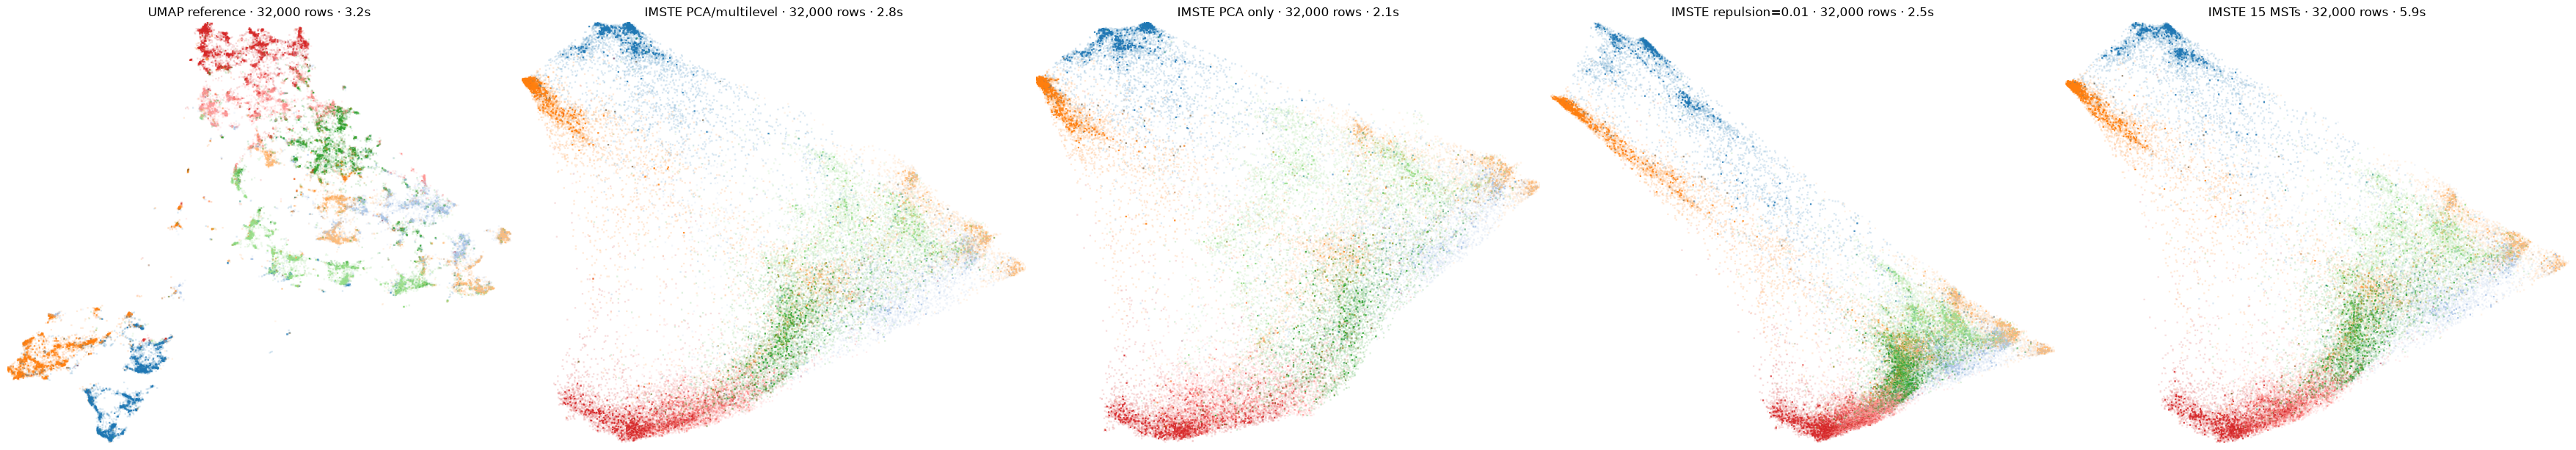

In [6]:
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from IPython.display import display
from imste.visualization import render_datashader_embedding

palette = plt.get_cmap("tab20")
class_order = list(labels_experiment.categories)
color_key = {label: to_hex(palette(i % palette.N)) for i, label in enumerate(class_order)}
label_values = pd.Series(np.asarray(labels_experiment)).astype(str)
layouts = [
    ("UMAP reference", Z_umap, umap_seconds),
    ("IMSTE PCA/multilevel", Z_imste_baseline, imste_baseline_seconds),
    ("IMSTE PCA only", Z_imste_pca_only, imste_pca_only_seconds),
    ("IMSTE repulsion=0.01", Z_imste_repulsion_001, imste_repulsion_001_seconds),
    ("IMSTE 15 MSTs", Z_imste_mst15, imste_mst15_seconds),
]
fig, axes = plt.subplots(1, len(layouts), figsize=(7 * len(layouts), 6), constrained_layout=True)
for ax, (name, coordinates, seconds) in zip(np.atleast_1d(axes), layouts):
    image = render_datashader_embedding(
        coordinates[:, :2], label_values, width=900, height=750,
        color_key=color_key, min_alpha=40, background="white", spread_px=1,
    )
    ax.imshow(image.to_pil())
    ax.set_title(f"{name} · {len(X_experiment):,} rows · {seconds:.1f}s")
    ax.set_axis_off()
display(fig)
plt.close(fig)
